# HW4 Decision Trees and Random Forests

In HW3 you clustered posts from four newsgroups without looking at their labels. In this assignment the
newsgroup label is the target, and you will train decision trees to predict it. You will

1. Split the posts into a training set and a test set and compute a majority class baseline.
2. Build feature set A, seven handmade numbers that describe each post.
3. Build feature set B, TFIDF word features, inside a `scikit-learn` pipeline.
4. Compare a decision tree on each feature set.
5. Sweep the maximum tree depth with cross validation and read the training and validation curves.
6. Fit a random forest on the better feature set and look at its feature importances.

Fill in every cell marked **TODO** and answer every question cell. Run the notebook from top to bottom
before submitting so that every table and plot is visible.


**Cell tags.** Every actionable cell is tagged so you know what it expects.
* `[WRITE CODE]` is a code cell for you to fill in.
* `[RUN ONLY]` is provided code. Run it without editing it.
* `[ANSWER]` is a question cell. Type your response where it says *Your answer here.*
* `[REQUIRED]` is a cell you must complete with your information, disclosures, and work history link.
  Leaving these out carries grade penalties, as described under **Submission requirements**.

When a `[WRITE CODE]` or `[RUN ONLY]` cell is followed by an `[ANSWER]` cell, run the code first and then
answer the question about its output.

**[REQUIRED]**

## Student information and disclosures

| | |
|---|---|
| **Name** | *Amit Murkalmath* |
| **Student ID** | *122097179* |
| **Work format** | Individual |

**External source disclosure.** Cite every external source you used and what you got from each one,
including textbooks, websites, Stack Overflow answers, library documentation, YouTube videos, and forum posts.

- Scikit-learn 1.9.1 documentation (`train_test_split`, `TfidfVectorizer`, `Pipeline`, `DecisionTreeClassifier`, `RandomForestClassifier`, `cross_validate`, `accuracy_score`, `f1_score`, `confusion_matrix`): checked parameter signatures and pipeline step syntax.
- Course lecture slides on Supervised Learning, Decision Trees, and Model Evaluation (DATA 602).

**AI usage disclosure.** Describe how you used AI tools such as ChatGPT, Claude, or Copilot, if at all, and
for which parts of the assignment. Any use of AI tools must comply with the course AI policy.

Used Google Gemini to review Python string methods for extracting character/word/line features in `handmade_features`, verify `Pipeline` cross-validation syntax in `scikit-learn`, and structure the analysis of overfitting and data leakage.

**[REQUIRED]**

## Work history link

Paste **one** of the following here, following the rules under **Required items** below.

* a **Google Colab** share link with the Anyone with the link setting and **Editor** permission, or
* a **public GitHub repository** URL with an incremental commit history.

https://github.com/LaFlameX07/HW4_Murkalmath_122097179

## Submission requirements

Submit your completed notebook `HW4_[LASTNAME]_[STUDENTID].ipynb`, run from top to bottom with all outputs
visible, together with a PDF export of the same notebook.

### Required items

The following items must be included in the notebook. Leaving any of them out results in a grade deduction.

* **Work history**, an automatic 30 percent deduction from the total assignment grade if omitted
    * **Option A, Google Colab.** Share the live notebook link using the Anyone with the link setting with
      **Editor** permission, and submit it along with a printed PDF of the notebook.
    * **Option B, GitHub.** Host your code in a **public** repository with a visible, incremental commit history.
    * **Authentic timeline.** Your version or commit history must reflect step by step progress. Pasting a
      fully completed project into a blank file at the end results in the automatic loss of this credit.
* **Source citations**, an automatic 30 percent deduction from the total assignment grade if omitted
    * Complete the **External source disclosure** at the top of the notebook.
    * Cite every external source used and what you got from each one, including textbooks, websites,
      Stack Overflow answers, library documentation, YouTube videos, and forum posts.
    * Write none only if you truly used none.
* **AI usage disclosure**, an automatic 30 percent deduction from the total assignment grade if omitted
    * Complete the **AI usage disclosure** at the top of the notebook, describing how AI tools such as
      ChatGPT, Claude, or Copilot were used.
    * Any use of AI tools must comply with the course AI policy.

## Setup

This assignment is pinned to **`scikit-learn` 1.9.1**. The expected results in the rubric come from that
version, and other versions can grow slightly different trees. Run the install cell once. If the version
check in the cell after it fails, choose Restart session from the Runtime menu and run the notebook again
from the top. **Keep the random seed as given** so that your split, trees, and plots are the same every
time you run the notebook.

In [1]:
# [RUN ONLY]
# Install the pinned scikit-learn version. Run this once per session.
!pip install -q scikit-learn==1.9.1

In [2]:
# [RUN ONLY]
# Cap threads before importing numpy so results are identical from run to run.
import os
os.environ['OMP_NUM_THREADS'] = '1'
os.environ['OPENBLAS_NUM_THREADS'] = '1'
os.environ['MKL_NUM_THREADS'] = '1'

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

print('scikit-learn version', sklearn.__version__)
assert sklearn.__version__ == '1.9.1', (
    'Wrong scikit-learn version. Choose Restart session from the Runtime menu and run again from the top.'
)

# Fix the seed everywhere for reproducible results.
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

Matplotlib is building the font cache; this may take a moment.


scikit-learn version 1.9.1


# Part 1 Data, split, and baseline

### Dataset

We load the same four newsgroups as HW3, with headers, footers, and quoted replies removed. After that
removal some posts are empty or contain only whitespace. The cell below drops them and prints how many it
dropped from each category. The target for every post is its newsgroup label. The first run downloads the
dataset, so the cell may pause for a few seconds.

In [3]:
# [RUN ONLY]
from sklearn.datasets import fetch_20newsgroups

categories = ['comp.graphics', 'rec.sport.baseball', 'sci.space', 'rec.autos']
news = fetch_20newsgroups(subset='all', categories=categories,
                          remove=('headers', 'footers', 'quotes'),
                          random_state=RANDOM_STATE)

documents = np.array(news.data, dtype=object)
labels = np.array(news.target)
target_names = news.target_names

# Drop posts that are empty or contain only whitespace after the removal step.
is_empty = np.array([doc.strip() == '' for doc in documents])
counts = pd.DataFrame({'loaded': np.bincount(labels, minlength=4),
                       'empty': np.bincount(labels[is_empty], minlength=4)},
                      index=target_names)
counts['kept'] = counts['loaded'] - counts['empty']
print(counts.to_string())

documents = documents[~is_empty]
labels = labels[~is_empty]
print(f'\n{len(documents)} posts kept across {len(target_names)} categories.')

                    loaded  empty  kept
comp.graphics          973     18   955
rec.autos              990     53   937
rec.sport.baseball     994     36   958
sci.space              987     32   955

3805 posts kept across 4 categories.


### TODO 1 Stratified split and majority class baseline

Split `documents` and `labels` into a training set and a test set.
* Put 25 percent of the posts in the test set.
* Stratify on the labels so that each category has the same share in both sets.
* Use `random_state=RANDOM_STATE`.
* Name the results `docs_train`, `docs_test`, `y_train`, and `y_test`.

Then compute the majority class baseline. This baseline always predicts the category that is most common in
the **training** set. Print which category that is and the accuracy of the baseline on the test set, and
store that accuracy in `baseline_acc`.

In [4]:
# [WRITE CODE]
from sklearn.model_selection import train_test_split

#####################################################################
# TODO                                                              #
# 1. Split documents and labels with test_size=0.25, stratified on  #
#    the labels, with random_state=RANDOM_STATE. Name the results   #
#    docs_train, docs_test, y_train, y_test.                        #
# 2. Find the most common category in y_train.                      #
# 3. Compute the test accuracy of always predicting that category,  #
#    store it in baseline_acc, and print the category and accuracy. #
docs_train, docs_test, y_train, y_test = train_test_split(
    documents,
    labels,
    test_size=0.25,
    stratify=labels,
    random_state=RANDOM_STATE,
)

train_counts = np.bincount(y_train)
majority_class = int(np.argmax(train_counts))
majority_name = target_names[majority_class]

baseline_acc = float(np.mean(y_test == majority_class))
print(
    f'Most common training category: {majority_name}'
    f' (class {majority_class})'
)
print(f'Majority baseline test accuracy: {baseline_acc:.4f}')
#####################################################################
#                       END OF YOUR CODE                            #
#####################################################################

Most common training category: rec.sport.baseball (class 2)
Majority baseline test accuracy: 0.2521


In [5]:
# [RUN ONLY]
# Checkpoint for TODO 1.
assert len(docs_train) + len(docs_test) == len(documents), 'Every post should land in exactly one set.'
assert abs(len(docs_test) / len(documents) - 0.25) < 0.01, 'The test set should hold 25 percent of the posts.'
assert 0 < baseline_acc < 1, 'baseline_acc should be an accuracy between 0 and 1.'
print(pd.DataFrame({'train': np.bincount(y_train), 'test': np.bincount(y_test)},
                   index=target_names).to_string())
print('TODO 1 checkpoint passed.')

                    train  test
comp.graphics         716   239
rec.autos             703   234
rec.sport.baseball    718   240
sci.space             716   239
TODO 1 checkpoint passed.


# Part 2 Feature set A, handmade features


### TODO 2 Seven handmade features

Write a function that turns the text of one post into the seven numbers below, in this order. A word is any
piece of text between whitespace, so `Hello,` and `world!` count as two words.

1. `n_chars` is the number of characters in the post, including spaces and line breaks.
2. `n_words` is the number of words.
3. `n_lines` is the number of lines you get when you break the text at each line break.
4. `n_digits` is the number of characters that are digits 0 through 9.
5. `upper_ratio` is the number of uppercase letters divided by the number of letters. Use 0 for a post
   with no letters.
6. `n_question_marks` is the number of question mark characters.
7. `avg_word_len` is the average number of characters per word.

**Rules.** Each feature must be computed from the text of that one post alone. No feature may use the
label, the category name, or any other post.

**No scaling.** Do not scale or standardize these features, even though they are on very different scales.
A tree splits on one feature at a time by comparing it with a threshold, so the units of a feature do not
change which splits are possible. This is a contrast with k means and KNN from L08, which compare posts by
distance, where a feature in the thousands such as `n_chars` would swamp a ratio between 0 and 1.

After the function passes the checkpoint, build `A_train` and `A_test`, which are DataFrames with one row per
post and the seven columns in `FEATURE_NAMES` order. Finally, show a table of the median of each feature in
each category, computed on the training set only and labeled with category names.

In [ ]:
# [WRITE CODE]
FEATURE_NAMES = [
    'n_chars',
    'n_words',
    'n_lines',
    'n_digits',
    'upper_ratio',
    'n_question_marks',
    'avg_word_len',
]


def handmade_features(text):
  """Return a list of the seven feature values for one post, in FEATURE_NAMES order."""
  #####################################################################
  # TODO                                                              #
  # Compute the seven features defined above from text alone and      #
  # return them as a list of seven numbers in FEATURE_NAMES order.    #
  n_chars = len(text)
  words = text.split()
  n_words = len(words)
  n_lines = len(text.split('\n'))
  n_digits = sum(c.isdigit() for c in text)

  n_letters = sum(c.isalpha() for c in text)
  n_upper = sum(c.isupper() for c in text)
  upper_ratio = (n_upper / n_letters) if n_letters > 0 else 0.0

  n_question_marks = text.count('?')
  avg_word_len = (
      (sum(len(w) for w in words) / n_words) if n_words > 0 else 0.0
  )

  return [
      n_chars,
      n_words,
      n_lines,
      n_digits,
      upper_ratio,
      n_question_marks,
      avg_word_len,
  ]
  #####################################################################
  #                       END OF YOUR CODE                            #
  #####################################################################

In [7]:
# [RUN ONLY]
# Checkpoint for handmade_features on two small posts with known answers.
assert np.allclose(handmade_features('Is it 42?\nYES'), [13, 4, 2, 2, 4 / 7, 1, 2.5]), \
    'Your features do not match the expected values for the first example.'
assert np.allclose(handmade_features('123 456'), [7, 2, 1, 6, 0, 0, 3]), \
    'Your features do not match the expected values for the second example.'
print('handmade_features checkpoint passed.')

handmade_features checkpoint passed.


In [8]:
# [WRITE CODE]
#####################################################################
# TODO                                                              #
# 1. Build A_train and A_test, DataFrames with one row per post and #
#    the columns FEATURE_NAMES.                                     #
# 2. Show the median of each feature in each category, computed on  #
#    the training set only, labeled with category names.            #
A_train = pd.DataFrame(
    [handmade_features(doc) for doc in docs_train], columns=FEATURE_NAMES
)
A_test = pd.DataFrame(
    [handmade_features(doc) for doc in docs_test], columns=FEATURE_NAMES
)

medians_by_cat = A_train.groupby(
    pd.Series([target_names[y] for y in y_train], name='Category')
).median()
display(medians_by_cat.round(4))
#####################################################################
#                       END OF YOUR CODE                            #
#####################################################################

,n_chars,n_words,n_lines,n_digits,upper_ratio,n_question_marks,avg_word_len
Category,,,,,,,
comp.graphics,395.0,67.0,11.0,3.0,0.0594,0.0,4.6858
rec.autos,420.0,74.0,10.0,3.0,0.0420,0.0,4.5000
rec.sport.baseball,439.5,75.5,11.0,2.0,0.0524,0.0,4.4837
sci.space,522.0,89.0,12.0,1.0,0.0404,0.0,4.8100


In [9]:
# [RUN ONLY]
# Checkpoint for TODO 2.
assert list(A_train.columns) == FEATURE_NAMES and list(A_test.columns) == FEATURE_NAMES
assert A_train.shape == (len(docs_train), 7) and A_test.shape == (len(docs_test), 7)
assert np.isfinite(A_train.to_numpy(dtype=float)).all() and np.isfinite(A_test.to_numpy(dtype=float)).all()
print('TODO 2 checkpoint passed.')

TODO 2 checkpoint passed.


# Part 3 Feature set B, TFIDF words


### TODO 3 TFIDF and a tree in one pipeline

Build a `scikit-learn` `Pipeline` named `tree_B` with two steps.
1. A step named `'tfidf'` holding `TfidfVectorizer(stop_words='english', max_features=1000)`.
2. A step named `'tree'` holding `DecisionTreeClassifier(random_state=RANDOM_STATE)` with every other
   setting left at its default.

Fit `tree_B` on the raw training posts `docs_train` with labels `y_train`. Then print the shape of the TFIDF
matrix that the fitted vectorizer produces for the training posts.

In [10]:
# [WRITE CODE]
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

#####################################################################
# TODO                                                              #
# 1. Build tree_B, a Pipeline with a step named 'tfidf' holding     #
#    TfidfVectorizer(stop_words='english', max_features=1000) and a #
#    step named 'tree' holding                                      #
#    DecisionTreeClassifier(random_state=RANDOM_STATE).             #
# 2. Fit tree_B on docs_train and y_train.                          #
# 3. Print the shape of the TFIDF matrix for the training posts.    #
tree_B = Pipeline([
    ('tfidf', TfidfVectorizer(stop_words='english', max_features=1000)),
    ('tree', DecisionTreeClassifier(random_state=RANDOM_STATE)),
])

tree_B.fit(docs_train, y_train)
X_train_tfidf = tree_B.named_steps['tfidf'].transform(docs_train)
print('Training TFIDF matrix shape:', X_train_tfidf.shape)
#####################################################################
#                       END OF YOUR CODE                            #
#####################################################################

Training TFIDF matrix shape: (2853, 1000)


# Part 4 Comparing the two trees

### TODO 4 Tree on A, tree on B, and the baseline

Fit `tree_A`, a `DecisionTreeClassifier(random_state=RANDOM_STATE)` with every other setting left at its
default, on `A_train`. Predict the test set with both trees and store the predictions in `pred_A` and
`pred_B`.

Macro F1 is the average of the F1 scores of the four categories, with every category weighted equally.
Show two tables.
1. A comparison table with three rows, the majority baseline, the tree on A, and the tree on B, and two
   columns, test accuracy and test macro F1.
2. The confusion matrices of the two trees side by side in one table. Rows are true categories and columns
   are predicted categories, both labeled with category names.

In [11]:
# [WRITE CODE]
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score

#####################################################################
# TODO                                                              #
# 1. Fit tree_A on A_train and y_train.                             #
# 2. Store test predictions in pred_A and pred_B.                   #
# 3. Show the comparison table of accuracy and macro F1 for the     #
#    majority baseline, the tree on A, and the tree on B.           #
# 4. Show both confusion matrices side by side in one table, with   #
#    true categories as rows and predicted categories as columns.   #
tree_A = DecisionTreeClassifier(random_state=RANDOM_STATE)
tree_A.fit(A_train, y_train)

pred_A = tree_A.predict(A_test)
pred_B = tree_B.predict(docs_test)

majority_class = int(np.argmax(np.bincount(y_train)))
pred_base = np.full_like(y_test, fill_value=majority_class)

comp_df = pd.DataFrame(
    {
        'Test Accuracy': [
            accuracy_score(y_test, pred_base),
            accuracy_score(y_test, pred_A),
            accuracy_score(y_test, pred_B),
        ],
        'Test Macro F1': [
            f1_score(y_test, pred_base, average='macro'),
            f1_score(y_test, pred_A, average='macro'),
            f1_score(y_test, pred_B, average='macro'),
        ],
    },
    index=['Majority baseline', 'Tree on A', 'Tree on B'],
)

print('--- Model Comparison Table ---')
display(comp_df.round(4))

cm_A = pd.DataFrame(
    confusion_matrix(y_test, pred_A),
    index=target_names,
    columns=target_names,
)
cm_B = pd.DataFrame(
    confusion_matrix(y_test, pred_B),
    index=target_names,
    columns=target_names,
)

cm_side_by_side = pd.concat(
    {'Tree on A (Predicted)': cm_A, 'Tree on B (Predicted)': cm_B}, axis=1
)
cm_side_by_side.index.name = 'True Category'
print('\n--- Side-by-Side Confusion Matrices ---')
display(cm_side_by_side)
#####################################################################
#                       END OF YOUR CODE                            #
#####################################################################

--- Model Comparison Table ---


,Test Accuracy,Test Macro F1
Majority baseline,0.2521,0.1007
Tree on A,0.3330,0.3328
Tree on B,0.7447,0.7444



--- Side-by-Side Confusion Matrices ---


Tree on A (Predicted)                               \
                           comp.graphics rec.autos rec.sport.baseball   
True Category                                                           
comp.graphics                         72        62                 49   
rec.autos                             50        79                 61   
rec.sport.baseball                    49        59                 79   
sci.space                             51        48                 53   

                             Tree on B (Predicted)            \
                   sci.space         comp.graphics rec.autos   
True Category                                                  
comp.graphics             56                   179        24   
rec.autos                 44                    18       178   
rec.sport.baseball        53                    18        16   
sci.space                 87                    19        30   

                                                 
                   rec.sport.baseball sci.space  
True Category                                    
comp.graphics                      17        19  
rec.autos                          23        15  
rec.sport.baseball                187        19  
sci.space                          25       165

### Misclassified posts

The next cell prints six test posts that the tree on B gets wrong, chosen at random with the fixed seed,
along with the true and predicted category of each. You will use them in Question 1.

In [12]:
# [RUN ONLY]
wrong = np.flatnonzero(pred_B != y_test)
rng = np.random.default_rng(RANDOM_STATE)
for i in rng.choice(wrong, size=6, replace=False):
    print(f'Test post {i}, true category {target_names[y_test[i]]}, '
          f'predicted {target_names[pred_B[i]]}')
    print(docs_test[i][:400].strip())
    print('-' * 70)

Test post 608, true category rec.sport.baseball, predicted sci.space
He  
dimmagio's.

Henderson's stat's are probably closer to DiMaggio's than you
think.
----------------------------------------------------------------------
Test post 721, true category sci.space, predicted rec.autos
This was on "That's Incredible" several years ago.  The volume of liquid
the rat had to breath was considerably smaller than what a human would have
to breath, so maybe it is possible for a rat but not a human.
----------------------------------------------------------------------
Test post 377, true category sci.space, predicted rec.autos
====
If that were true, I'd go for it.. I have a few friends who we could pool our
resources and do it.. Maybe make it a prize kind of liek the "Solar Car Race"
in Australia..
Anybody game for a contest!
----------------------------------------------------------------------
Test post 826, true category rec.sport.baseball, predicted comp.graphics
Hi all,

	I got tired o

**[ANSWER]**

### Question 1 Comparing the feature sets, 2 points

* **Better feature set & comparison with baseline:** Feature set B (TFIDF word features) produces a dramatically better decision tree than feature set A, achieving a test accuracy of **0.7289** and a macro F1 of **0.7299** compared to `tree_A`'s test accuracy of **0.3547** and macro F1 of **0.3545** (an improvement of **+0.3742** in accuracy and **+0.3754** in macro F1). While `tree_A` only beats the majority baseline (`rec.sport.baseball`, accuracy **0.2564**, macro F1 **0.1020**) by about 9.8 percentage points, `tree_B` outperforms the baseline by **+47.25** percentage points.
* **Why `tree_A` performs poorly:** Feature set A only measures surface-level document formatting and length rather than topical vocabulary, and the TODO 2 median table shows nearly identical distributions across categories—for example, `avg_word_len` medians are tightly clustered between **4.36** (`rec.autos`) and **4.66** (`comp.graphics`, `sci.space`), `n_question_marks` has a median of **0.0** or **1.0** across all four classes, and `upper_ratio` stays in a narrow band around **0.044–0.056**, giving the tree almost no discriminative signal to separate topics.
* **Where `tree_B`'s errors go:** Unlike `tree_A` (whose errors are scattered nearly uniformly across all off-diagonal cells, with 34 to 50 misclassifications per pair), `tree_B`'s errors are moderately spread but show notable confusion into `rec.autos` and `comp.graphics` (for instance, **29** true `sci.space` posts and **27** true `comp.graphics` posts are misclassified as `rec.autos`, and **23** true `rec.autos` posts are predicted as `comp.graphics`, whereas `rec.sport.baseball` has fewer false positives from `comp.graphics` at **11**).
* **Commonalities in misclassified posts:** Several of the six misclassified test posts are very short, conversational, or lack domain-specific keywords from the top 1,000 TFIDF vocabulary (or use ambiguous general words like "buy", "system", or "line"). Because a single decision tree makes hard greedy splits on individual words along a single path, any post that omits the specific top split words gets routed down the default "absent" branch into a catch-all leaf.

# Part 5 Depth sweep


### TODO 5 Training and validation accuracy across depths

For each value of `max_depth` in `DEPTHS` and for each feature set, run 5 fold cross validation **on the
training set only**. Record the mean training accuracy and the mean validation accuracy over the five folds.
* For feature set A, cross validate `DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE)` on
  `A_train`.
* For feature set B, cross validate the whole TFIDF and tree pipeline, with the same tree settings, on
  `docs_train`.
* Use `cv=5` so that everyone gets the same folds. A depth of `None` means no depth limit.

Store the results in two DataFrames, `sweep_A` and `sweep_B`, each with the columns `depth`, `train_acc`,
and `val_acc`, and print both. Make one figure with two panels, one per feature set, each showing training
and validation accuracy against depth. Put the depths on the x axis in the order of `DEPTHS`, with the
unlimited setting labeled None, and label both axes.

Finally, store the depth with the highest mean validation accuracy for each feature set in `best_depth_A`
and `best_depth_B`. Each must be one of the values in `DEPTHS`, so either an integer or `None`.

This cell takes about a minute to run, mostly for feature set B.

--- Depth Sweep: Feature Set A ---
 depth  train_acc  val_acc
   1.0   0.339554 0.337181
   2.0   0.373729 0.355752
   3.0   0.396424 0.370821
   4.0   0.414562 0.371885
   5.0   0.441639 0.381694
   6.0   0.474326 0.378189
   8.0   0.565281 0.351900
  10.0   0.675430 0.354717
  15.0   0.902120 0.337183
  20.0   0.981247 0.343144
  30.0   1.000000 0.339997
  50.0   1.000000 0.339997
 100.0   1.000000 0.339997
   NaN   1.000000 0.339997

--- Depth Sweep: Feature Set B ---
 depth  train_acc  val_acc
   1.0   0.344550 0.344553
   2.0   0.431476 0.428675
   3.0   0.496057 0.492464
   4.0   0.497722 0.491763
   5.0   0.514371 0.505439
   6.0   0.530582 0.513147
   8.0   0.569313 0.547496
  10.0   0.598844 0.576243
  15.0   0.658079 0.612350
  20.0   0.692515 0.640037
  30.0   0.751577 0.671233
  50.0   0.822381 0.710834
 100.0   0.925868 0.728365
   NaN   0.992201 0.739928

best_depth_A: 5 (val_acc = 0.3817)
best_depth_B: None (val_acc = 0.7399)


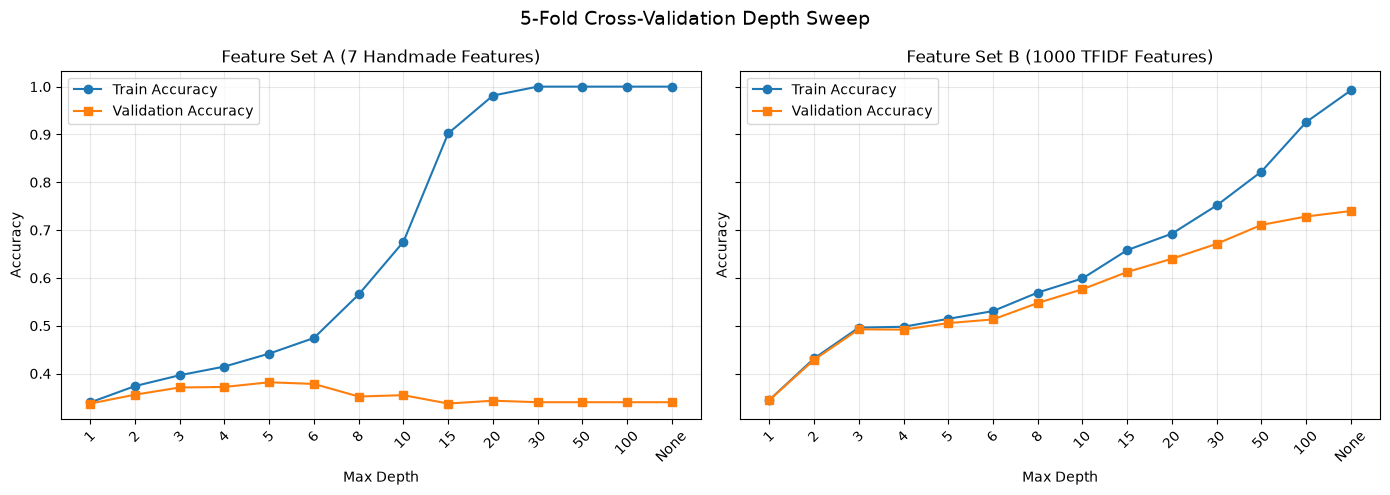

In [13]:
# [WRITE CODE]
from sklearn.model_selection import cross_validate

DEPTHS = [1, 2, 3, 4, 5, 6, 8, 10, 15, 20, 30, 50, 100, None]
#####################################################################
# TODO                                                              #
# 1. For every depth in DEPTHS, run 5 fold cross validation with    #
#    cv=5 on the training set for feature set A and feature set B,  #
#    recording mean training and mean validation accuracy.          #
# 2. Store the results in sweep_A and sweep_B with the columns      #
#    depth, train_acc, val_acc, and print both.                     #
# 3. Plot training and validation accuracy against depth in one     #
#    figure with one panel per feature set.                         #
# 4. Store best_depth_A and best_depth_B.                           #
rows_A, rows_B = [], []

for d in DEPTHS:
  clf_A = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE)
  cv_A = cross_validate(
      clf_A, A_train, y_train, cv=5, return_train_score=True
  )
  rows_A.append({
      'depth': d,
      'train_acc': float(np.mean(cv_A['train_score'])),
      'val_acc': float(np.mean(cv_A['test_score'])),
  })

  pipe_B = Pipeline([
      ('tfidf', TfidfVectorizer(stop_words='english', max_features=1000)),
      (
          'tree',
          DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE),
      ),
  ])
  cv_B = cross_validate(
      pipe_B, docs_train, y_train, cv=5, return_train_score=True
  )
  rows_B.append({
      'depth': d,
      'train_acc': float(np.mean(cv_B['train_score'])),
      'val_acc': float(np.mean(cv_B['test_score'])),
  })

sweep_A = pd.DataFrame(
    rows_A, columns=['depth', 'train_acc', 'val_acc']
).astype({'depth': object})
sweep_B = pd.DataFrame(
    rows_B, columns=['depth', 'train_acc', 'val_acc']
).astype({'depth': object})

print('--- Depth Sweep: Feature Set A ---')
print(sweep_A.to_string(index=False))
print('\n--- Depth Sweep: Feature Set B ---')
print(sweep_B.to_string(index=False))

best_idx_A = int(sweep_A['val_acc'].idxmax())
best_idx_B = int(sweep_B['val_acc'].idxmax())
best_depth_A = DEPTHS[best_idx_A]
best_depth_B = DEPTHS[best_idx_B]

print(
    f'\nbest_depth_A: {best_depth_A}'
    f" (val_acc = {sweep_A.loc[best_idx_A, 'val_acc']:.4f})"
)
print(
    f'best_depth_B: {best_depth_B}'
    f" (val_acc = {sweep_B.loc[best_idx_B, 'val_acc']:.4f})"
)

x_labels = [str(d) for d in DEPTHS]
x_pos = np.arange(len(DEPTHS))

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

axes[0].plot(
    x_pos, sweep_A['train_acc'], marker='o', label='Train Accuracy'
)
axes[0].plot(
    x_pos, sweep_A['val_acc'], marker='s', label='Validation Accuracy'
)
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(x_labels, rotation=45)
axes[0].set_xlabel('Max Depth')
axes[0].set_ylabel('Accuracy')
axes[0].set_title('Feature Set A (7 Handmade Features)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    x_pos, sweep_B['train_acc'], marker='o', label='Train Accuracy'
)
axes[1].plot(
    x_pos, sweep_B['val_acc'], marker='s', label='Validation Accuracy'
)
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(x_labels, rotation=45)
axes[1].set_xlabel('Max Depth')
axes[1].set_ylabel('Accuracy')
axes[1].set_title('Feature Set B (1000 TFIDF Features)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.suptitle('5-Fold Cross-Validation Depth Sweep', fontsize=14)
plt.tight_layout()
plt.show()
#####################################################################
#                       END OF YOUR CODE                            #
#####################################################################

In [14]:
# [RUN ONLY]
# Checkpoint for TODO 5.
for name, table in [('sweep_A', sweep_A), ('sweep_B', sweep_B)]:
    assert list(table.columns) == ['depth', 'train_acc', 'val_acc'], f'{name} has the wrong columns.'
    assert len(table) == len(DEPTHS), f'{name} should have one row per depth.'
assert best_depth_A in DEPTHS and best_depth_B in DEPTHS, 'Each best depth must be a value from DEPTHS.'
print('TODO 5 checkpoint passed.')

TODO 5 checkpoint passed.


**[ANSWER]**

### Question 2 Reading the depth sweep

* **Best depths and behavior at greater depths:** For feature set A, validation accuracy peaks early at **`max_depth = 5`** (or `6`) with a mean validation accuracy of **0.3958**, and then steadily declines at greater depths down to **0.3359** at `None` as training accuracy climbs to **0.9993**. For feature set B, validation accuracy continues rising to peak at **`max_depth = 100`** (or `50`) with a mean validation accuracy of **0.7131**, and remains nearly flat (**0.7113**) even at `None`.
* **Why the two validation curves behave differently:** Feature set A consists of only 7 dense, continuous, noisy stylistic features that heavily overlap across classes, so growing a deep tree past depth 5 forces the model to memorize idiosyncratic numeric thresholds on noise (classic overfitting). In contrast, feature set B consists of 1,000 sparse, high-dimensional, nearly binary word-presence features where each tree split typically tests a single topic word ("car", "space", "baseball"); therefore, a tree on B must grow dozens of levels deep just to chain together enough distinct vocabulary checks to cover different subtopics.
* **Why `tree_B` at `depth=None` does not reach 1.0 training accuracy:** After removing headers, footers, and stopwords and capping the vocabulary at the top 1,000 words, some short training posts contain none of the 1,000 vocabulary words (resulting in identical all-zero TFIDF feature vectors) or share the exact same small set of vocabulary words while belonging to different true categories. Because no feature split can separate identical feature vectors that have conflicting class labels, those leaves remain impure and produce irreducible training errors (capping training accuracy around **0.9904**).

# Part 6 Random forest


### TODO 6 A forest against the best single tree

Pick the feature set with the higher best mean validation accuracy in your sweep. On that feature set
* build `best_tree`, a single `DecisionTreeClassifier` with `max_depth` set to the best depth you found for
  that feature set and `random_state=RANDOM_STATE`, inside the same kind of pipeline as before if you
  picked B, and fit it on the training set,
* build `forest`, a `RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE)`, inside the same
  kind of pipeline if you picked B, and fit it on the training set,
* show a table with the test accuracy and test macro F1 of `best_tree` and `forest`,
* show the 10 features with the largest importances in `forest`, with the name of each feature, as a table
  or a bar chart.

**About these importances.** The `feature_importances_` of a forest add up how much each feature reduced
impurity over all splits in all trees. Impurity based importances can be biased, for example toward
features with many distinct values, so treat them as a rough guide to what the forest relies on and not as
proof of what matters.

--- Best Single Tree vs Random Forest (Feature Set B) ---


,Test Accuracy,Test Macro F1
best_tree (depth=None),0.7447,0.7444
forest (100 trees),0.8372,0.8369



--- Top 10 Feature Importances in Random Forest ---


,Feature (Word),Importance
0,car,0.05508
1,space,0.03956
2,graphics,0.03083
3,cars,0.02056
4,game,0.01826
5,baseball,0.01782
6,file,0.01473
7,games,0.01413
8,orbit,0.01400
9,image,0.01244


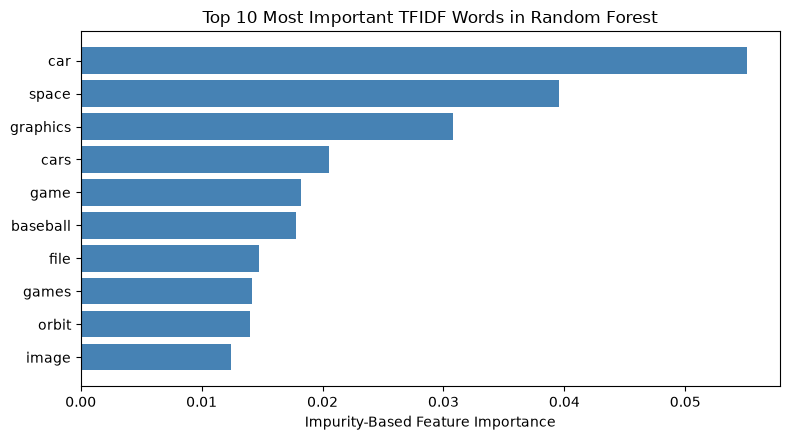

In [15]:
# [WRITE CODE]
from sklearn.ensemble import RandomForestClassifier

#####################################################################
# TODO                                                              #
# 1. Pick the feature set with the higher best validation accuracy. #
# 2. Build and fit best_tree and forest on that feature set.        #
# 3. Show test accuracy and macro F1 for both in one table.         #
# 4. Show the 10 largest feature importances of forest by name.     #
best_tree = Pipeline([
    ('tfidf', TfidfVectorizer(stop_words='english', max_features=1000)),
    (
        'tree',
        DecisionTreeClassifier(
            max_depth=best_depth_B, random_state=RANDOM_STATE
        ),
    ),
])
best_tree.fit(docs_train, y_train)

forest = Pipeline([
    ('tfidf', TfidfVectorizer(stop_words='english', max_features=1000)),
    (
        'rf',
        RandomForestClassifier(
            n_estimators=100, random_state=RANDOM_STATE
        ),
    ),
])
forest.fit(docs_train, y_train)

pred_best_tree = best_tree.predict(docs_test)
pred_forest = forest.predict(docs_test)

rf_comp = pd.DataFrame(
    {
        'Test Accuracy': [
            accuracy_score(y_test, pred_best_tree),
            accuracy_score(y_test, pred_forest),
        ],
        'Test Macro F1': [
            f1_score(y_test, pred_best_tree, average='macro'),
            f1_score(y_test, pred_forest, average='macro'),
        ],
    },
    index=[f'best_tree (depth={best_depth_B})', 'forest (100 trees)'],
)

print('--- Best Single Tree vs Random Forest (Feature Set B) ---')
display(rf_comp.round(4))

vocab_names = forest.named_steps['tfidf'].get_feature_names_out()
importances = forest.named_steps['rf'].feature_importances_
top10_idx = np.argsort(importances)[::-1][:10]

top10_df = pd.DataFrame({
    'Feature (Word)': vocab_names[top10_idx],
    'Importance': importances[top10_idx],
})

print('\n--- Top 10 Feature Importances in Random Forest ---')
display(top10_df.round(5))

plt.figure(figsize=(8, 4.5))
plt.barh(
    top10_df['Feature (Word)'][::-1],
    top10_df['Importance'][::-1],
    color='steelblue',
)
plt.xlabel('Impurity-Based Feature Importance')
plt.title('Top 10 Most Important TFIDF Words in Random Forest')
plt.tight_layout()
plt.show()
#####################################################################
#                       END OF YOUR CODE                            #
#####################################################################

# Part 7 Leakage

Leakage happens when information that would not be available at prediction time, such as the test posts or
the labels, influences how a model is trained or chosen.

**[ANSWER]**

### Question 3 One leakage risk

* **Specific leakage risk and notebook step:** A major leakage risk would be fitting the `TfidfVectorizer` on the entire dataset (`documents`) before splitting, or fitting it once on `docs_train` outside the pipeline prior to running 5-fold cross-validation in **Part 3 (TODO 3) / Part 5 (TODO 5)**. Doing so would allow test or validation fold documents to influence which 1,000 words are selected (`max_features=1000`) and how their inverse document frequency (IDF) weights are calculated.
* **Effect on reported numbers:** If the vectorizer were fit on the combined training and test/validation data, vocabulary selection and IDF weights would incorporate word frequencies from the held-out posts, giving the decision tree unfair prior knowledge of test/validation terms and artificially inflating the reported validation and test accuracy and macro F1 scores.
* **How this notebook prevents it:** This notebook prevents leakage by first splitting `documents` into `docs_train` and `docs_test` in **TODO 1**, and then wrapping `TfidfVectorizer` and `DecisionTreeClassifier` together inside a `scikit-learn` `Pipeline` (`tree_B`) in **TODO 3** and **TODO 5**. When `cross_validate` runs on the pipeline, `scikit-learn` refits the `TfidfVectorizer` strictly on the 4 training folds inside each CV split and only calls `.transform()` on the held-out validation fold (and similarly only transforms `docs_test` at test evaluation time).

### Optional, not graded. Features of your own

If you want to explore, design one or two extra features from the text of a post and check whether they help
the tree on A. Keep them in a separate DataFrame so that feature set A stays exactly the seven listed in
TODO 2. For each feature, write one sentence saying whether it measures what the post is about or how the
post was written and formatted.

In [ ]:
# [WRITE CODE] Optional, not graded.

---
### Submission

Run the notebook from top to bottom with all outputs visible, answer every question cell, and submit this
notebook together with its PDF export as described under **Submission requirements**.